In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from pathlib import Path

In [13]:
GRAPHS = {
    "dblp": Path("sssp_res/com-dblp-weighted"),
    "lj":   Path("sssp_res/com-lj-weighted"),
    "youtube":  Path("sssp_res/youtube-sym-weighted"),
}

In [14]:
def get_stat(df, region, category):
    s = df.loc[(df["REGION"] == region) & (df["CATEGORY"] == category), "TOTAL"]
    s = pd.to_numeric(s, errors="coerce")
    return s.iloc[0] if len(s) else np.nan

In [15]:
def median_stat(df, region_pat, category_pat):
    m = df["REGION"].str.fullmatch(region_pat) & df["CATEGORY"].str.fullmatch(category_pat)
    return pd.to_numeric(df.loc[m, "TOTAL"], errors="coerce").median()

In [16]:
rows = []
for graph, folder in GRAPHS.items():
    for path in sorted(folder.glob("n*_t*.csv")):
        m = re.fullmatch(r"n(\d+)_t(\d+)\.csv", path.name)
        if not m:
            continue
        n, t = int(m.group(1)), int(m.group(2))

        df = pd.read_csv(path, skipinitialspace=True)
        df["REGION"] = df["REGION"].astype(str).str.strip()
        df["CATEGORY"] = df["CATEGORY"].astype(str).str.strip()

        rows.append({
            "graph": graph,
            "hosts": n,
            "threads": t,
            # Timer_0 ... Timer_9 в регионе SSSP: время алгоритма целиком (TimerTotal не попадает)
            "median_timer_ms": median_stat(df, r"SSSP", r"Timer_\d+"),
            # SSSP_0 ... SSSP_9, категория Time: только вычислительные циклы
            "median_loop_ms": median_stat(df, r"SSSP_\d+", r"Time"),
            # Gluon, Sync_SSSP_N: время синхронизации между хостами
            "median_sync_ms": median_stat(df, r"Gluon", r"Sync_SSSP_\d+"),
            # Gluon, ReduceSendBytes_SSSP_N: байты, отправленные за один прогон
            "median_reduce_send_bytes": median_stat(df, r"Gluon", r"ReduceSendBytes_SSSP_\d+"),
            # Одно значение на файл
            "replication_factor": get_stat(df, "Gluon", "ReplicationFactor"),
            "graph_construct_time": get_stat(df, "DistBench", "GraphConstructTime"),
            "iter_num": median_stat(df, r"SSSP",  r"NumIterations_\d+"),
            "work_items_num": median_stat(df, r"SSSP",  r"NumWorkItems_\d+"),
        })

result = (pd.DataFrame(rows)
            .sort_values(["graph", "hosts", "threads"])
            .reset_index(drop=True))
result.to_csv("sssp_results_table.csv", index=False)
print(result.to_string(index=False))

  graph  hosts  threads  median_timer_ms  median_loop_ms  median_sync_ms  median_reduce_send_bytes  replication_factor  graph_construct_time  iter_num  work_items_num
   dblp      1        1          65.4850         65.4340          0.0030                       NaN             1.00000                49.443      19.0      10173931.0
   dblp      1        2          34.5445         34.5050          0.0030                       NaN             1.00000                27.454      20.0       9953084.5
   dblp      1        3          23.1155         23.0825          0.0030                       NaN             1.00000                23.500      19.0       9881317.0
   dblp      1        4          25.3750         25.3410          0.0020                       NaN             1.00000                22.511      19.0       9999708.0
   dblp      1        5          26.1310         26.0975          0.0035                       NaN             1.00000                21.698      20.0       9636637.

In [17]:
result = (pd.DataFrame(rows)
            .sort_values(["graph", "hosts", "threads"])
            .reset_index(drop=True))
result.to_csv("sssp_stats.csv", index=False)

In [18]:
df = pd.read_csv('sssp_stats.csv')
df

,graph,hosts,threads,median_timer_ms,median_loop_ms,median_sync_ms,median_reduce_send_bytes,replication_factor,graph_construct_time,iter_num,work_items_num
0,dblp,1,1,65.4850,65.4340,0.0030,NaN,1.00000,49.443,19.0,10173931.0
1,dblp,1,2,34.5445,34.5050,0.0030,NaN,1.00000,27.454,20.0,9953084.5
2,dblp,1,3,23.1155,23.0825,0.0030,NaN,1.00000,23.500,19.0,9881317.0
3,dblp,1,4,25.3750,25.3410,0.0020,NaN,1.00000,22.511,19.0,9999708.0
4,dblp,1,5,26.1310,26.0975,0.0035,NaN,1.00000,21.698,20.0,9636637.5
5,dblp,1,6,26.5425,26.5045,0.0030,NaN,1.00000,21.823,20.0,9834120.5
6,dblp,1,7,28.3815,28.3315,0.0020,NaN,1.00000,20.565,21.0,10023875.0
7,dblp,1,8,83.7500,83.6965,0.0040,NaN,1.00000,24.452,20.0,9423474.5
8,dblp,2,1,67.4215,51.2250,22.7025,5001578.0,1.47877,34.380,38.0,12497971.5
9,dblp,2,2,71.4270,54.9565,20.8025,4717352.0,1.47877,28.524,44.0,12134890.5


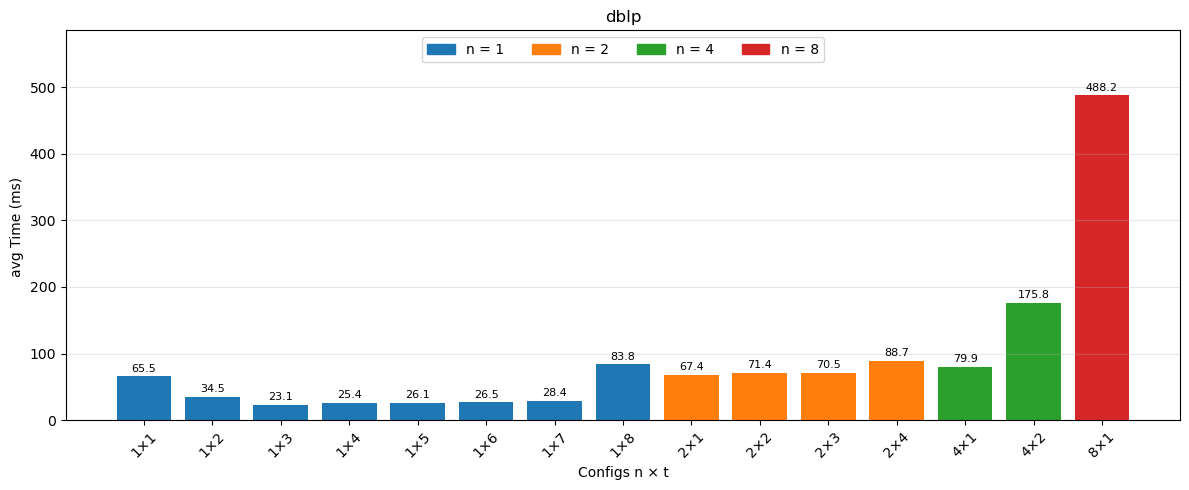

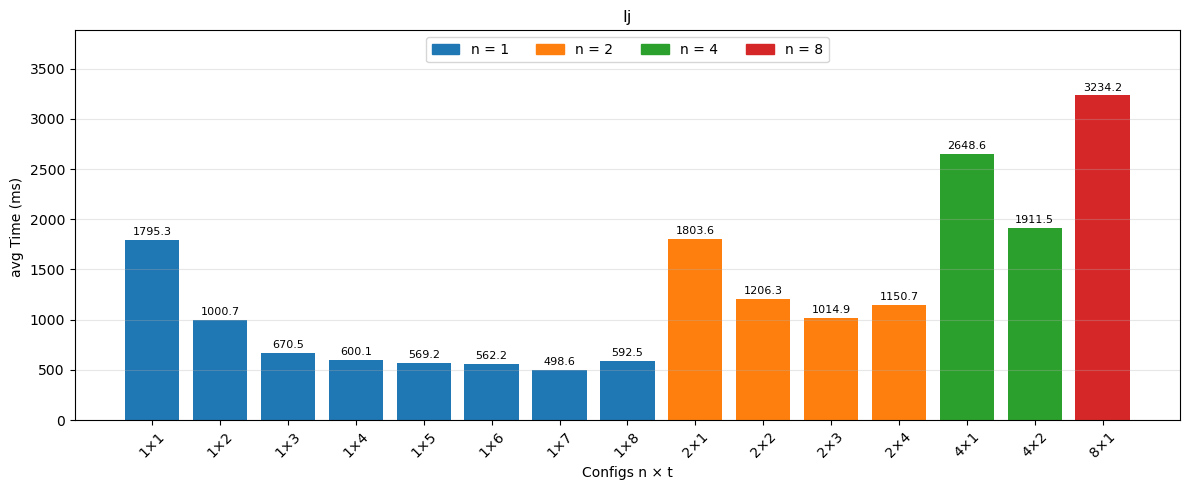

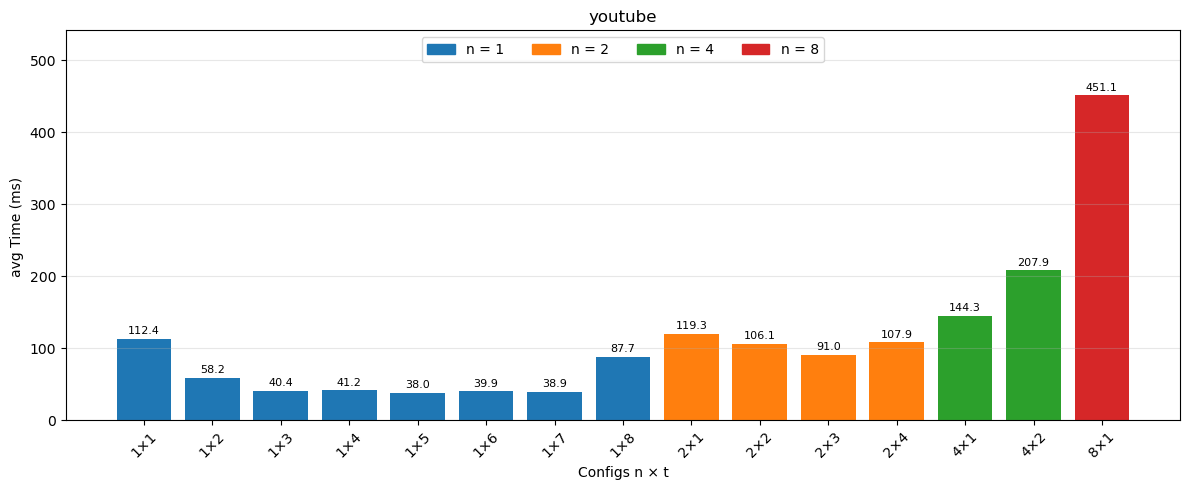

In [20]:
df = df.sort_values(["graph", "hosts", "threads"])

hosts_values = sorted(df["hosts"].unique())
cmap = plt.get_cmap("tab10")
color_of = {n: cmap(i) for i, n in enumerate(hosts_values)}

for g in df["graph"].unique():
    sub = df[df["graph"] == g]
    labels = [f"{n}×{t}" for n, t in zip(sub["hosts"], sub["threads"])]
    colors = [color_of[n] for n in sub["hosts"]]

    fig, ax = plt.subplots(figsize=(12, 5))
    bars = ax.bar(labels, sub["median_timer_ms"], color=colors)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)   # значение над столбцом

    ax.set_title(g)
    ax.set_xlabel("Configs n × t")
    ax.set_ylabel("avg Time (ms) ")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.2)                                        # место под легенду и подписи сверху

    # Легенда по центру сверху, в одну строку
    present = sorted(sub["hosts"].unique())
    ax.legend(handles=[Patch(color=color_of[n], label=f"n = {n}") for n in present],
              loc="upper center", ncol=len(present))

    fig.tight_layout()
    fig.savefig(f"avg_time_{g}.png", dpi=150)
    plt.show()

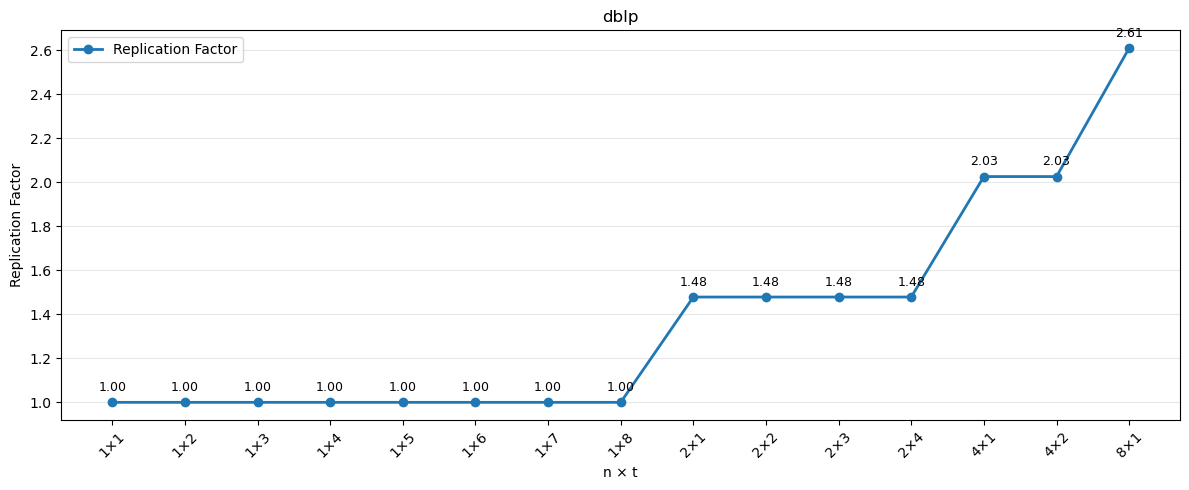

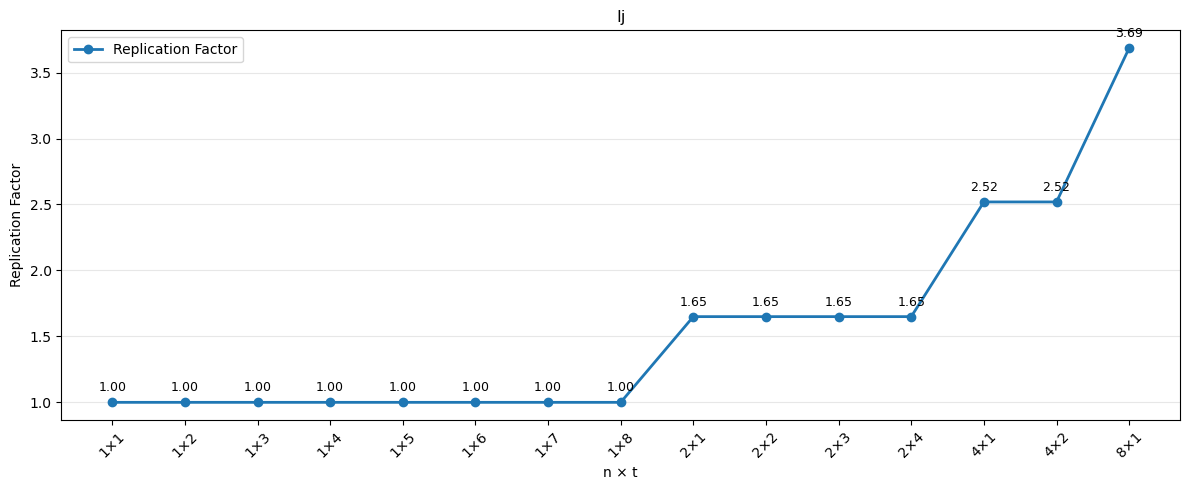

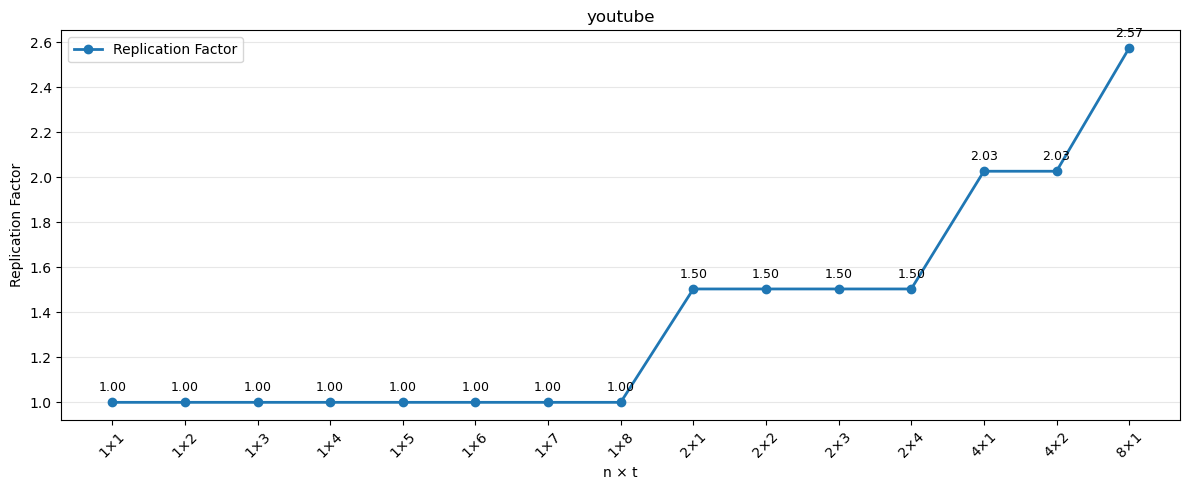

In [3]:
df = df.sort_values(["graph", "hosts", "threads"])

for g in df["graph"].unique():
    sub = df[df["graph"] == g].copy()

    # Конфигурация на оси X
    sub["config"] = (
        sub["hosts"].astype(str) + "×" +
        sub["threads"].astype(str)
    )

    fig, ax = plt.subplots(figsize=(12, 5))

    # Line 1 — nodes
    ax.plot(
        sub["config"],
        sub["replication_factor"],
        marker="o",
        linewidth=2,
        label="Replication Factor"
    )

    # Подписи значений nodes
    for i, value in enumerate(sub["replication_factor"]):
        ax.annotate(
            f"{value:.2f}",
            (i, value),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.set_title(g)
    ax.set_xlabel("n × t")
    ax.set_ylabel("Replication Factor")

    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    fig.tight_layout()
    fig.savefig(f"replication_factor_{g}.png", dpi=150)
    plt.show()

# Количество итераций

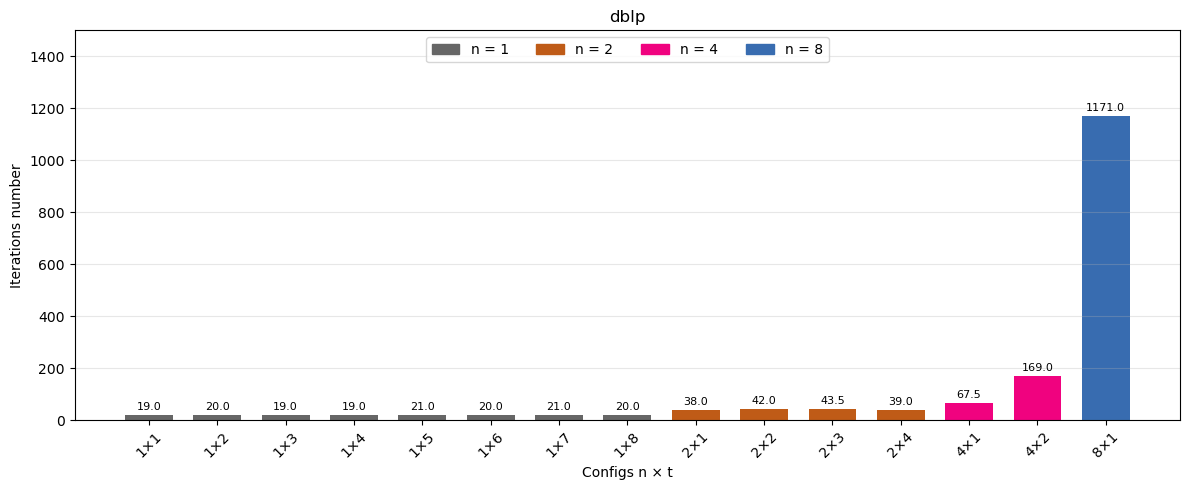

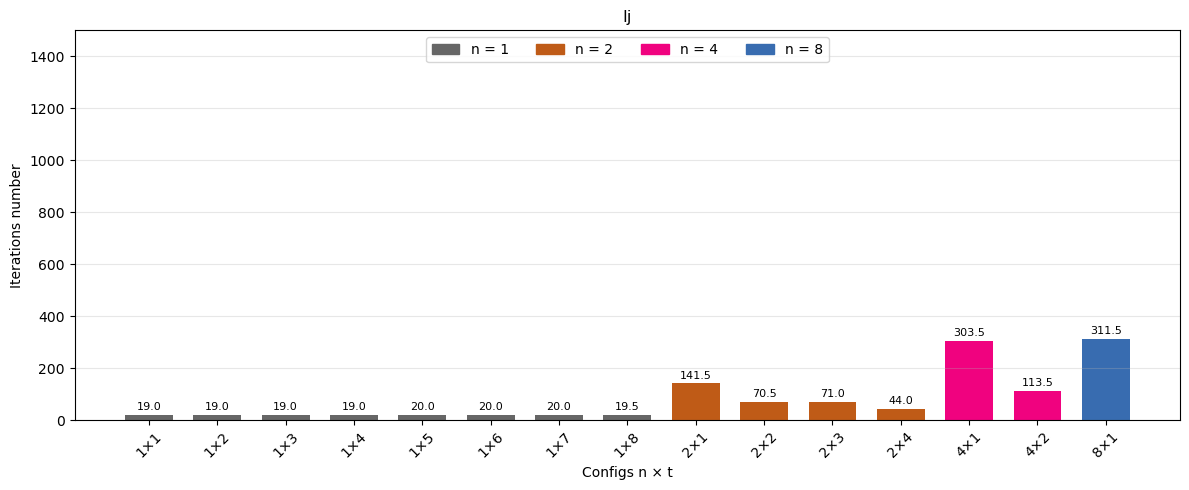

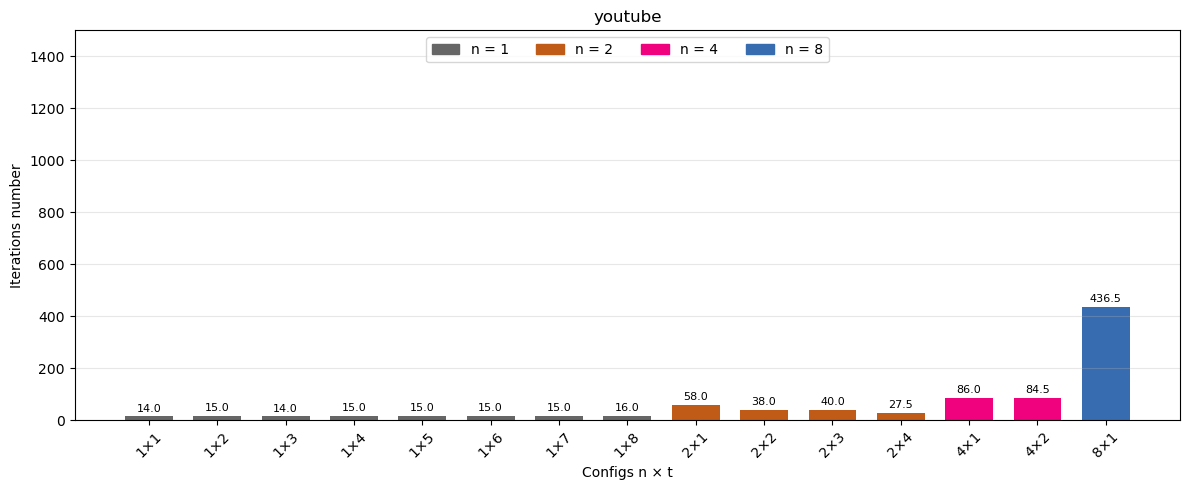

In [9]:
df = df.sort_values(["graph", "hosts", "threads"])

hosts_values = sorted(df["hosts"].unique())
cmap = plt.get_cmap("Accent_r")
color_of = {n: cmap(i) for i, n in enumerate(hosts_values)}

for g in df["graph"].unique():
    sub = df[df["graph"] == g]
    labels = [f"{n}×{t}" for n, t in zip(sub["hosts"], sub["threads"])]
    colors = [color_of[n] for n in sub["hosts"]]

    fig, ax = plt.subplots(figsize=(12, 5))
    bars = ax.bar(labels, sub["iter_num"], color=colors, width=0.7)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)   # значение над столбцом

    ax.set_title(g)
    ax.set_xlabel("Configs n × t")
    ax.set_ylabel("Iterations number")
    ax.set_ylim(0, 1500)  # ось Y от 0 до 700
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.2)                                       # место под легенду и подписи сверху

    # Легенда по центру сверху, в одну строку
    present = sorted(sub["hosts"].unique())
    ax.legend(handles=[Patch(color=color_of[n], label=f"n = {n}") for n in present],
              loc="upper center", ncol=len(present))

    fig.tight_layout()
    fig.savefig(f"iters_{g}.png", dpi=150)
    plt.show()

# Изменение таймера

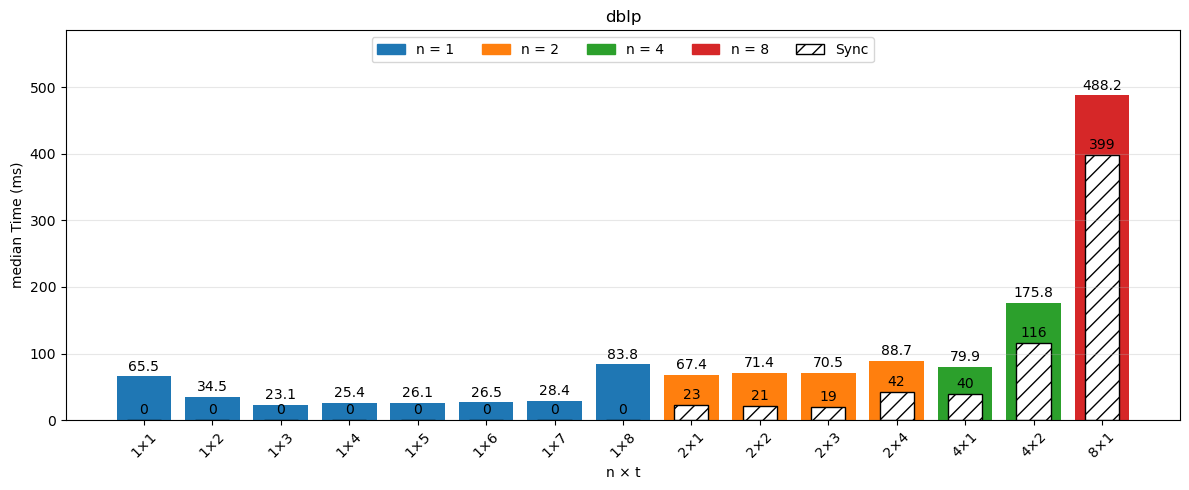

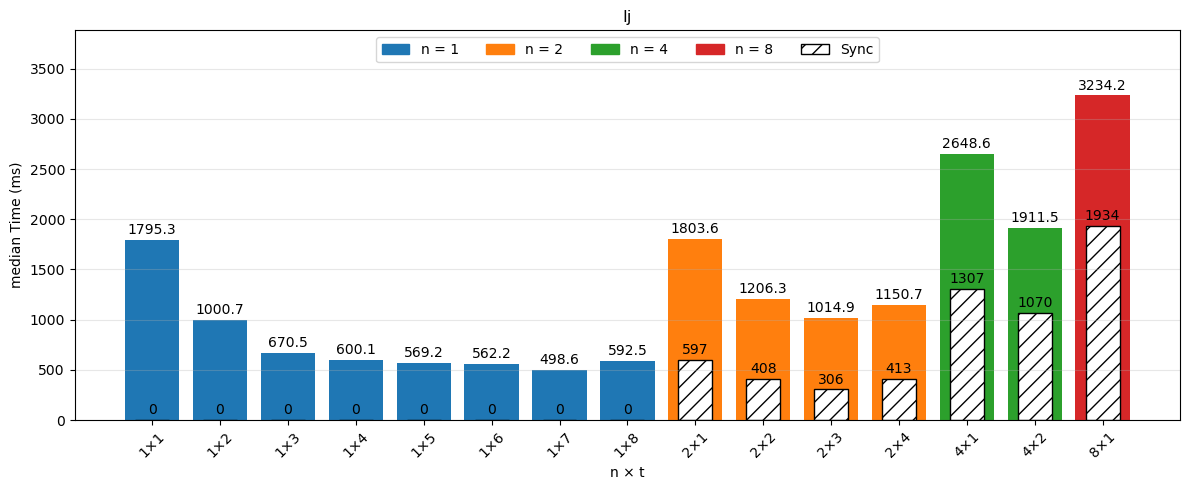

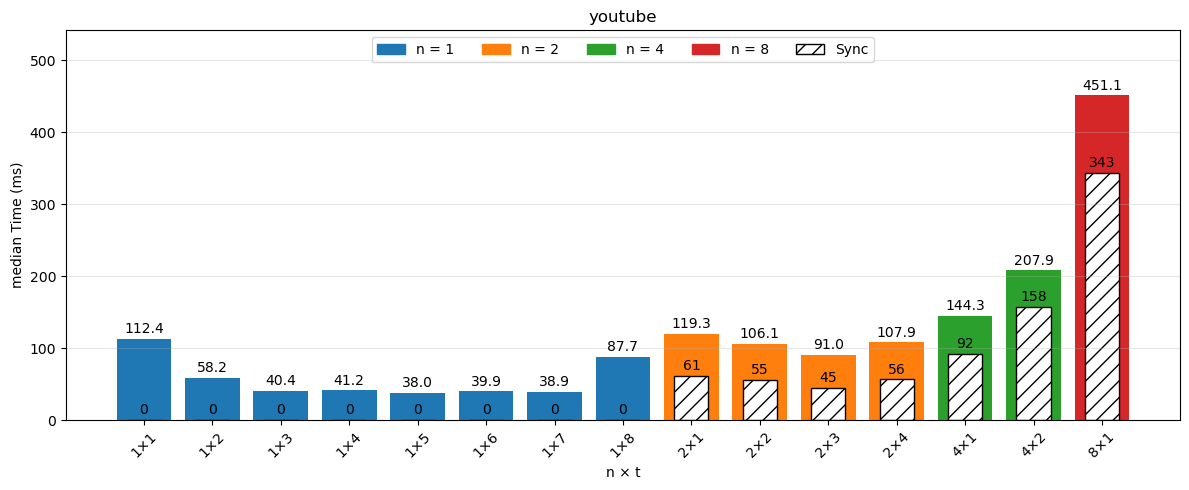

In [25]:
df = df.sort_values(["graph", "hosts", "threads"])
hosts_values = sorted(df["hosts"].unique())
cmap = plt.get_cmap("tab10")
color_of = {n: cmap(i) for i, n in enumerate(hosts_values)}

for g in df["graph"].unique():
    sub = df[df["graph"] == g]
    labels = [f"{n}×{t}" for n, t in zip(sub["hosts"], sub["threads"])]
    colors = [color_of[n] for n in sub["hosts"]]
    timer = sub["median_timer_ms"].values
    sync = sub["median_sync_ms"].values            # для n = 1 здесь NaN: столбца не будет

    fig, ax = plt.subplots(figsize=(12, 5))
    bars = ax.bar(labels, timer, color=colors, width=0.8)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=10)

    # Узкий столбец внутри: Sync
    sbars = ax.bar(labels, sync, width=0.5, color="white", edgecolor="black",
                   hatch="//")
    ymax = np.nanmax(timer)
    ax.bar_label(sbars, labels=["" if np.isnan(v) else f"{v:.0f}" for v in sync],
                 label_type="edge", padding=2, fontsize=10,
                 bbox=dict(facecolor="none", edgecolor="none"))
    
    # ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)   # значение над столбцом

    ax.set_title(g)
    ax.set_xlabel("n × t")
    ax.set_ylabel("median Time (ms)")
    # ax.set_ylim(0, 600)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.2)

    present = sorted(sub["hosts"].unique())
    handles = [Patch(color=color_of[n], label=f"n = {n}") for n in present]
    handles.append(Patch(facecolor="white", edgecolor="black", hatch="//", label="Sync"))
    ax.legend(handles=handles, loc="upper center", ncol=len(handles))

    fig.tight_layout()
    fig.savefig(f"time_with_sync_{g}.png", dpi=150)
    plt.show()